# Assignment 2 – Calibrated Similarity-Guided SLERP Layer Merging (GPT-2)

**Goal:** improve adjacent-layer merging from Assignment 1 (metric: **perplexity, lower is better**) on GPT-2 + WikiText-2.

## Idea and where it comes from
| Component | What we do | Source paper (from the shared set) |
|---|---|---|
| Choose *which* adjacent pair to merge | Score every pair (L, L+1) with **linear CKA + cosine** similarity of their hidden states (z-scored); shortlist the top-k | **Chain-of-Merging (CoM)**, Zhang et al., CVPR 2026 – §3.3 *Adaptive Layer Matching*, Eqs. 4–7 (CKA/HSIC, semantic cosine); also **MKA**, Liu et al., arXiv 2406.16330 – §4.5 (similarity matrix between layers) |
| *How* to merge two layers | **SLERP** (spherical interpolation) with magnitude re-scaling instead of plain linear averaging | CoM §3.4, Eqs. 10–12 |
| Merge weight | Not a fixed 0.5: prior from the similarity score (CoM Eq. 9) and then **tuned on a tiny calibration set**; separate weight for the attention and MLP sub-modules | CoM Eq. 9 + Fig. 3 / Table 6 (weight range matters); MKA §7.3 / Table 3 (adaptive ratio beats fixed ratio) |
| Repeat to compress more | **Iterative/greedy** merging: after each merge re-compute similarities on the new model | MKA §6.5 / Table 4 (iterative is better than one-shot) |
| Small calibration data | A few thousand tokens of the **train** split used only for scoring/tuning (evaluation is on validation/test) | Reference-sample idea of Attribution-guided Pruning (arXiv 2506.13727, §3.1) |

**Calibration budget:** ~4k tokens for similarity, ~8k tokens for tuning (both from the WikiText-2 *train* split). No gradient training.

In [1]:
!pip install -q transformers datasets accelerate pandas psutil

In [2]:
import copy, math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| Transformers:", transformers.__version__, "| device:", device)

PyTorch: 2.11.0+cu130 | Transformers: 5.17.0 | device: cuda


In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

MODEL_ID = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def load_fresh_model():
    m = AutoModelForCausalLM.from_pretrained(MODEL_ID)
    m.config.use_cache = False
    return m.to(device).eval()

base_model = load_fresh_model()
print("layers:", len(base_model.transformer.h))

dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
train_text = "\n\n".join(dataset["train"]["text"])
validation_text = "\n\n".join(dataset["validation"]["text"])
test_text = "\n\n".join(dataset["test"]["text"])

def get_ids(text, max_tokens=None):
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False)["input_ids"][0]
    return ids[:max_tokens] if max_tokens else ids

# Evaluation sets: same protocol as Assignment 1 (first 50k tokens, block size 512)
val_ids  = get_ids(validation_text, 50000)
test_ids = get_ids(test_text, 50000)
# Calibration sets: TRAIN split only (never used for reporting)
train_ids = get_ids(train_text[:400000], 20000)
sim_ids = train_ids[:4096]        # for layer-similarity scores
cal_ids = train_ids[4096:4096+8192]  # for tuning merge weights
print(len(val_ids), len(test_ids), len(sim_ids), len(cal_ids))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (251048 > 1024). Running this sequence through the model will result in indexing errors


50000 50000 4096 8192


In [4]:
@torch.no_grad()
def ppl_ids(model, ids, block_size=512, batch=8):
    """Same perplexity as Assignment 1 (non-overlapping 512-token blocks), just batched."""
    model.eval()
    n = len(ids) // block_size
    x_all = ids[: n * block_size].view(n, block_size)
    nll, cnt = 0.0, 0
    for i in range(0, n, batch):
        x = x_all[i:i+batch].to(device)
        loss = model(input_ids=x, labels=x, use_cache=False).loss
        c = x.shape[0] * (x.shape[1] - 1)
        nll += loss.item() * c
        cnt += c
    return math.exp(nll / cnt)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def set_blocks(model, blocks):
    model.transformer.h = nn.ModuleList(blocks)
    model.config.n_layer = len(blocks)
    return model

orig_val  = ppl_ids(base_model, val_ids)
orig_test = ppl_ids(base_model, test_ids)
print(f"Original GPT-2  val PPL = {orig_val:.3f} | test PPL = {orig_test:.3f} | params = {count_params(base_model):,}")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Original GPT-2  val PPL = 33.938 | test PPL = 38.831 | params = 124,439,808


## 1. Assignment-1 baselines (re-implemented, same layer pair L=5)

In [5]:
def remove_layer(model, L):
    m = copy.deepcopy(model)
    b = list(m.transformer.h)
    return set_blocks(m, b[:L] + b[L+1:])

def weighted_average_layer(model, L, alpha=0.5):
    m = copy.deepcopy(model)
    b = list(m.transformer.h)
    merged = copy.deepcopy(b[L+1])
    p1 = dict(b[L].named_parameters())
    with torch.no_grad():
        for name, p in merged.named_parameters():
            p.copy_(alpha * p1[name] + (1 - alpha) * p.data.clone())
    return set_blocks(m, b[:L] + [merged] + b[L+2:])

# ---- affine merge (Assignment 1) ----
@torch.no_grad()
def collect_hidden_states(model, ids, L, chunk_size=256, total_tokens=4096):
    ids = ids[:total_tokens]
    Xs, Y1s, Y2s = [], [], []
    for s in range(0, len(ids) - chunk_size + 1, chunk_size):
        x = ids[s:s+chunk_size].unsqueeze(0).to(device)
        h = model(input_ids=x, output_hidden_states=True, use_cache=False).hidden_states
        for lst, t in ((Xs, h[L]), (Y1s, h[L+1]), (Y2s, h[L+2])):
            lst.append(t.reshape(-1, t.shape[-1]).cpu().float())
    return torch.cat(Xs), torch.cat(Y1s), torch.cat(Y2s)

def fit_affine(X, Y, ridge=1e-4):
    n, d = X.shape
    Xa = torch.cat([X, torch.ones(n, 1, dtype=X.dtype)], dim=1)
    I = torch.eye(d + 1, dtype=X.dtype); I[-1, -1] = 0
    sol = torch.linalg.solve(Xa.T @ Xa + ridge * I, Xa.T @ Y)
    return sol[:-1], sol[-1]

class AffineMergedBlock(nn.Module):
    def __init__(self, A, b):
        super().__init__()
        d = A.shape[0]
        self.linear = nn.Linear(d, d)
        with torch.no_grad():
            self.linear.weight.copy_(A.T); self.linear.bias.copy_(b)
    def forward(self, hidden_states, *args, **kwargs):
        return self.linear(hidden_states)

def affine_multiply_model(model, L, ids):
    X, Y1, Y2 = collect_hidden_states(model, ids, L)
    A1, b1 = fit_affine(X, Y1); A2, b2 = fit_affine(Y1, Y2)
    A, b = A1 @ A2, b1 @ A2 + b2
    m = copy.deepcopy(model)
    blk = AffineMergedBlock(A, b).to(device)
    bl = list(m.transformer.h)
    return set_blocks(m, bl[:L] + [blk] + bl[L+2:])

L0 = 5
rows_base = []
for name, fn in [
    ("A1: remove layer 5",              lambda: remove_layer(base_model, L0)),
    ("A1: linear average 0.5 (L=5)",    lambda: weighted_average_layer(base_model, L0, 0.5)),
    ("A1: affine multiply (L=5)",       lambda: affine_multiply_model(base_model, L0, train_ids)),
]:
    m = fn()
    rows_base.append(dict(method=name, layers=len(m.transformer.h), params=count_params(m),
                          val_ppl=ppl_ids(m, val_ids), test_ppl=ppl_ids(m, test_ids)))
    del m; torch.cuda.empty_cache()
df_base = pd.DataFrame(rows_base)
df_base

,method,layers,params,val_ppl,test_ppl
0,A1: remove layer 5,11,117351936,40.873509,46.693044
1,A1: linear average 0.5 (L=5),11,117351936,111.362777,120.586025
2,A1: affine multiply (L=5),11,110854656,53.317191,57.467462


## 2. Proposed method

**Pair scoring (CoM Eqs. 4–7).** For adjacent blocks *i, i+1* we take their output hidden states (z-scored per feature, first token dropped because GPT-2 puts huge outlier activations there), and compute
`S = ( linear-CKA + mean token cosine ) / 2`.

**SLERP merge (CoM Eqs. 10–12).** Every parameter tensor is flattened, normalised, interpolated on the sphere with weight `w` (weight of the later layer), then rescaled with `||a||^(1-w) * ||b||^w`. If two tensors are almost parallel we fall back to linear interpolation.

**Calibrated weights.** The weight `w` is grid-searched on `cal_ids` (train split) for the top-k most similar pairs, then refined separately for the attention group (`ln_1`, `attn`) and the MLP group (`ln_2`, `mlp`). `mode ∈ {slerp, lerp}` is also selected on calibration data.

**Iterative (MKA §6.5).** Repeat after every merge on the already-merged model.

In [6]:
# ---------- similarity ----------
@torch.no_grad()
def block_outputs(model, ids, block_size=512):
    """Output hidden state of every transformer block (first token of each sequence dropped)."""
    blocks = model.transformer.h
    store = [[] for _ in blocks]
    hooks = []
    for i, b in enumerate(blocks):
        def hook(mod, inp, out, i=i):
            h = out[0] if isinstance(out, tuple) else out
            store[i].append(h[:, 1:, :].reshape(-1, h.shape[-1]).float().cpu())
        hooks.append(b.register_forward_hook(hook))
    n = len(ids) // block_size
    x = ids[: n * block_size].view(n, block_size).to(device)
    model.eval()
    try:
        model(input_ids=x, use_cache=False)
    finally:
        for h in hooks: h.remove()
    return [torch.cat(s) for s in store]

def zscore(X):
    return (X - X.mean(0, keepdim=True)) / (X.std(0, keepdim=True) + 1e-6)

def linear_cka(X, Y):
    X = X - X.mean(0, keepdim=True); Y = Y - Y.mean(0, keepdim=True)
    num = (X.T @ Y).norm() ** 2
    return (num / ((X.T @ X).norm() * (Y.T @ Y).norm())).item()

def pair_score(X, Y):
    Xz, Yz = zscore(X), zscore(Y)
    cka = linear_cka(Xz, Yz)
    cos = F.cosine_similarity(Xz, Yz, dim=1).mean().item()
    return 0.5 * (cka + cos), cka, cos

def prior_w(S, tau=0.4, wmin=0.3, wmax=0.7):
    """CoM Eq. 9: dynamic weight from the (normalised) matching score."""
    sn = min(max((S - tau) / (1.0 - tau), 0.0), 1.0)
    return wmin + (wmax - wmin) * sn

# ---------- merging ----------
def lerp_t(a, b, w):
    return (1 - w) * a + w * b

def slerp_t(a, b, w, eps=1e-8, thresh=0.9995):
    a32, b32 = a.float().flatten(), b.float().flatten()
    na, nb = a32.norm(), b32.norm()
    if na < eps or nb < eps:
        return lerp_t(a, b, w)
    ah, bh = a32 / na, b32 / nb
    dot = torch.clamp(torch.dot(ah, bh), -1.0, 1.0)
    if dot.abs() > thresh:
        return lerp_t(a, b, w)
    om = torch.acos(dot); so = torch.sin(om)
    direction = (torch.sin((1 - w) * om) / so) * ah + (torch.sin(w * om) / so) * bh
    out = direction * (na ** (1 - w) * nb ** w)
    return out.view_as(a).to(a.dtype)

def merge_blocks(bA, bB, w_attn, w_mlp, mode="slerp"):
    """Merge block A (layer L) into B (layer L+1). w = weight of the LATER layer."""
    f = slerp_t if mode == "slerp" else lerp_t
    merged = copy.deepcopy(bB)
    pA = dict(bA.named_parameters())
    with torch.no_grad():
        for name, p in merged.named_parameters():
            w = w_attn if name.startswith(("ln_1", "attn")) else w_mlp
            p.copy_(f(pA[name].data, p.data.clone(), w))
    return merged

@torch.no_grad()
def try_merge(model, L, w_attn, w_mlp, mode, ids):
    """Temporarily swap in the merged block, return (PPL, merged_block)."""
    orig = model.transformer.h
    blocks = list(orig)
    merged = merge_blocks(blocks[L], blocks[L+1], w_attn, w_mlp, mode)
    set_blocks(model, blocks[:L] + [merged] + blocks[L+2:])
    try:
        p = ppl_ids(model, ids)
    finally:
        set_blocks(model, blocks)
    return p, merged

In [7]:
GRID = [round(x, 2) for x in np.arange(0.0, 1.01, 0.1)]

def compress(model, n_merges, cal_ids, sim_ids, modes=("slerp", "lerp"), tune=True,
             fixed_w=None, topk=4, per_group=True, grid=GRID, verbose=True):
    """Greedy iterative adjacent-layer merging. Returns (compressed_model, log)."""
    model = copy.deepcopy(model)
    log = []
    for step in range(n_merges):
        outs = block_outputs(model, sim_ids)
        nb = len(model.transformer.h)
        scored = sorted([(pair_score(outs[i], outs[i+1])[0], i) for i in range(nb - 1)], reverse=True)
        blocks = list(model.transformer.h)

        if not tune:                              # similarity-only variants (no calibration)
            S, L = scored[0]
            w = prior_w(S) if fixed_w is None else fixed_w
            merged = merge_blocks(blocks[L], blocks[L+1], w, w, modes[0])
            info = dict(layer=L, S=round(S, 3), mode=modes[0], w_attn=round(w, 3), w_mlp=round(w, 3))
        else:                                     # calibrated variant
            best = (float("inf"), None)
            for S, L in scored[:topk]:
                for mode in modes:
                    for w in grid:
                        p, _ = try_merge(model, L, w, w, mode, cal_ids)
                        if p < best[0]:
                            best = (p, (L, mode, w, w, S))
            p_best, (L, mode, wa, wm, S) = best
            if per_group:                         # refine attn / mlp weights separately
                for _ in range(2):
                    for g in ("attn", "mlp"):
                        for w in grid:
                            a, m_ = (w, wm) if g == "attn" else (wa, w)
                            p, _ = try_merge(model, L, a, m_, mode, cal_ids)
                            if p < p_best:
                                p_best, wa, wm = p, a, m_
            merged = merge_blocks(blocks[L], blocks[L+1], wa, wm, mode)
            info = dict(layer=L, S=round(S, 3), mode=mode, w_attn=wa, w_mlp=wm, cal_ppl=round(p_best, 2))

        set_blocks(model, blocks[:L] + [merged] + blocks[L+2:])
        log.append(info)
        if verbose: print(f"  step {step+1}: {info}")
    return model, log

## 3. Single merge: ablation (L chosen by method, evaluated on val/test)

In [8]:
VARIANTS = {
    "MKA-style: sim-selected pair + linear 0.5":
        dict(modes=("lerp",), tune=False, fixed_w=0.5, topk=1, per_group=False),
    "CoM-style: sim-selected pair + SLERP, w=prior(S)":
        dict(modes=("slerp",), tune=False, fixed_w=None, topk=1, per_group=False),
    "+ calibrated shared w (SLERP)":
        dict(modes=("slerp",), tune=True, topk=4, per_group=False),
    "OURS: + per-group w + mode search":
        dict(modes=("slerp", "lerp"), tune=True, topk=4, per_group=True),
}

rows = []
t0 = time.time()
for name, cfg in VARIANTS.items():
    print(name)
    m, log = compress(base_model, 1, cal_ids, sim_ids, **cfg)
    rows.append(dict(method=name, merges=1, layers=len(m.transformer.h), params=count_params(m),
                     val_ppl=ppl_ids(m, val_ids), test_ppl=ppl_ids(m, test_ids), steps=str(log)))
    del m; torch.cuda.empty_cache()
print(f"done in {time.time()-t0:.0f}s")

df_single = pd.concat([df_base.assign(merges=1, steps=""), pd.DataFrame(rows)], ignore_index=True)
df_single.insert(0, "orig_val_ppl", orig_val)
df_single[["method", "merges", "layers", "params", "val_ppl", "test_ppl", "steps"]]

MKA-style: sim-selected pair + linear 0.5
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
CoM-style: sim-selected pair + SLERP, w=prior(S)
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'slerp', 'w_attn': 0.668, 'w_mlp': 0.668}
+ calibrated shared w (SLERP)
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'slerp', 'w_attn': np.float64(1.0), 'w_mlp': np.float64(1.0), 'cal_ppl': 45.52}
OURS: + per-group w + mode search
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_attn': np.float64(1.0), 'w_mlp': np.float64(1.0), 'cal_ppl': 45.52}
done in 154s


,method,merges,layers,params,val_ppl,test_ppl,steps
0,A1: remove layer 5,1,11,117351936,40.873509,46.693044,
1,A1: linear average 0.5 (L=5),1,11,117351936,111.362777,120.586025,
2,A1: affine multiply (L=5),1,11,110854656,53.317191,57.467462,
3,MKA-style: sim-selected pair + linear 0.5,1,11,117351936,171.959252,194.649747,"[{'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_a..."
4,"CoM-style: sim-selected pair + SLERP, w=prior(S)",1,11,117351936,131.228065,151.188965,"[{'layer': 3, 'S': 0.951, 'mode': 'slerp', 'w_..."
5,+ calibrated shared w (SLERP),1,11,117351936,38.297623,43.853157,"[{'layer': 3, 'S': 0.951, 'mode': 'slerp', 'w_..."
6,OURS: + per-group w + mode search,1,11,117351936,38.297620,43.853158,"[{'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_a..."


## 4. More compression: 1, 2, 3 and 4 merges (iterative)

In [9]:
rows_multi = []
for name, cfg in VARIANTS.items():
    for n in [2, 3, 4]:
        print(name, "| merges =", n)
        m, log = compress(base_model, n, cal_ids, sim_ids, **cfg)
        rows_multi.append(dict(method=name, merges=n, layers=len(m.transformer.h), params=count_params(m),
                               val_ppl=ppl_ids(m, val_ids), test_ppl=ppl_ids(m, test_ids), steps=str(log)))
        del m; torch.cuda.empty_cache()

df_all = pd.concat([pd.DataFrame(rows), pd.DataFrame(rows_multi)], ignore_index=True)
df_all = df_all.sort_values(["merges", "val_ppl"]).reset_index(drop=True)
df_all[["method", "merges", "layers", "params", "val_ppl", "test_ppl"]]

MKA-style: sim-selected pair + linear 0.5 | merges = 2
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 2: {'layer': 2, 'S': 0.982, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
MKA-style: sim-selected pair + linear 0.5 | merges = 3
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 2: {'layer': 2, 'S': 0.982, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 3: {'layer': 1, 'S': 0.986, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
MKA-style: sim-selected pair + linear 0.5 | merges = 4
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 2: {'layer': 2, 'S': 0.982, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 3: {'layer': 1, 'S': 0.986, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
  step 4: {'layer': 0, 'S': 0.977, 'mode': 'lerp', 'w_attn': 0.5, 'w_mlp': 0.5}
CoM-style: sim-selected pair + SLERP, w=prior(S) | merges = 2
  step 1: {'layer': 3, 'S': 0.951, 'mode': 'slerp', '

,method,merges,layers,params,val_ppl,test_ppl
0,OURS: + per-group w + mode search,1,11,117351936,38.297620,43.853158
1,+ calibrated shared w (SLERP),1,11,117351936,38.297623,43.853157
2,"CoM-style: sim-selected pair + SLERP, w=prior(S)",1,11,117351936,131.228065,151.188965
3,MKA-style: sim-selected pair + linear 0.5,1,11,117351936,171.959252,194.649747
4,+ calibrated shared w (SLERP),2,10,110264064,41.797816,47.254008
5,OURS: + per-group w + mode search,2,10,110264064,41.797818,47.254010
6,"CoM-style: sim-selected pair + SLERP, w=prior(S)",2,10,110264064,289.706032,354.273706
7,MKA-style: sim-selected pair + linear 0.5,2,10,110264064,364.853132,415.613360
8,+ calibrated shared w (SLERP),3,9,103176192,48.500510,55.010774
9,OURS: + per-group w + mode search,3,9,103176192,48.657951,55.272635


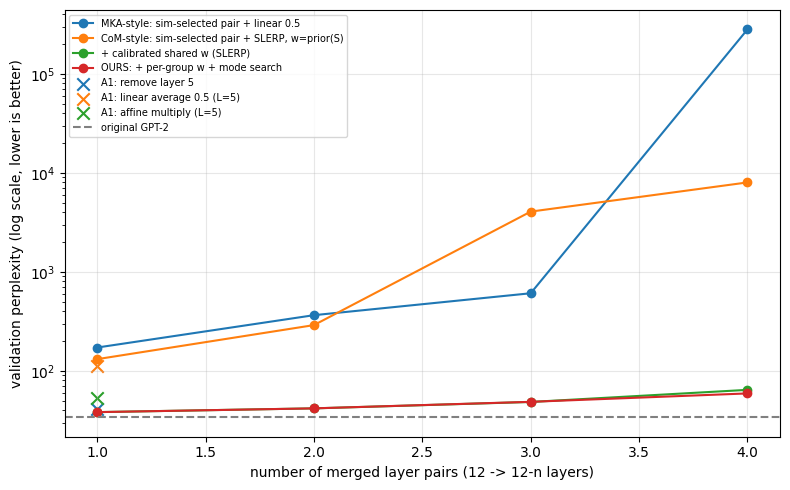

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
for name in VARIANTS:
    d = df_all[df_all.method == name].sort_values("merges")
    plt.plot(d.merges, d.val_ppl, marker="o", label=name)
for _, r in df_base.iterrows():
    plt.scatter([1], [r.val_ppl], marker="x", s=80, label=r.method)
plt.axhline(orig_val, ls="--", c="gray", label="original GPT-2")
plt.yscale("log"); plt.xlabel("number of merged layer pairs (12 -> 12-n layers)")
plt.ylabel("validation perplexity (log scale, lower is better)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Final summary (use this table in the report) and save

In [11]:
best_row = df_all[df_all.method.str.startswith("OURS")].sort_values("merges")
summary = pd.concat([
    pd.DataFrame([dict(method="Original GPT-2", merges=0, layers=12, params=count_params(base_model),
                       val_ppl=orig_val, test_ppl=orig_test)]),
    df_base.assign(merges=1),
    best_row[["method", "merges", "layers", "params", "val_ppl", "test_ppl"]],
], ignore_index=True)
print(summary.to_string(index=False))

summary.to_csv("summary_results.csv", index=False)
df_all.to_csv("all_results_with_steps.csv", index=False)
print("saved summary_results.csv and all_results_with_steps.csv")

                           method  merges  layers    params    val_ppl   test_ppl
                   Original GPT-2       0      12 124439808  33.938325  38.830639
               A1: remove layer 5       1      11 117351936  40.873509  46.693044
     A1: linear average 0.5 (L=5)       1      11 117351936 111.362777 120.586025
        A1: affine multiply (L=5)       1      11 110854656  53.317191  57.467462
OURS: + per-group w + mode search       1      11 117351936  38.297620  43.853158
OURS: + per-group w + mode search       2      10 110264064  41.797818  47.254010
OURS: + per-group w + mode search       3       9 103176192  48.657951  55.272635
OURS: + per-group w + mode search       4       8  96088320  59.166552  66.875939
saved summary_results.csv and all_results_with_steps.csv
